<a href="https://www.kaggle.com/code/mohammednafayali/date-fruit-classification-using-ann-shap?scriptVersionId=362080038" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/muratkokludataset/date-fruit-datasets/Date_Fruit_Datasets/Date_Fruit_Datasets.arff
/kaggle/input/datasets/muratkokludataset/date-fruit-datasets/Date_Fruit_Datasets/Date_Fruit_Datasets.xlsx
/kaggle/input/datasets/muratkokludataset/date-fruit-datasets/Date_Fruit_Datasets/Date_Fruit_Datasets_Citation_Request.txt


# 1. Environment Setup & Data Loading
We begin by importing the essential data science, visualization, and deep learning libraries, and loading the Date Fruit dataset into a Pandas DataFrame.


In [2]:
df=pd.read_excel("/kaggle/input/datasets/muratkokludataset/date-fruit-datasets/Date_Fruit_Datasets/Date_Fruit_Datasets.xlsx")
df.head()

,AREA,PERIMETER,MAJOR_AXIS,MINOR_AXIS,ECCENTRICITY,EQDIASQ,SOLIDITY,CONVEX_AREA,EXTENT,ASPECT_RATIO,...,KurtosisRR,KurtosisRG,KurtosisRB,EntropyRR,EntropyRG,EntropyRB,ALLdaub4RR,ALLdaub4RG,ALLdaub4RB,Class
0,422163,2378.908,837.8484,645.6693,0.6373,733.1539,0.9947,424428,0.7831,1.2976,...,3.2370,2.9574,4.2287,-59191263232,-50714214400,-39922372608,58.7255,54.9554,47.8400,BERHI
1,338136,2085.144,723.8198,595.2073,0.5690,656.1464,0.9974,339014,0.7795,1.2161,...,2.6228,2.6350,3.1704,-34233065472,-37462601728,-31477794816,50.0259,52.8168,47.8315,BERHI
2,526843,2647.394,940.7379,715.3638,0.6494,819.0222,0.9962,528876,0.7657,1.3150,...,3.7516,3.8611,4.7192,-93948354560,-74738221056,-60311207936,65.4772,59.2860,51.9378,BERHI
3,416063,2351.210,827.9804,645.2988,0.6266,727.8378,0.9948,418255,0.7759,1.2831,...,5.0401,8.6136,8.2618,-32074307584,-32060925952,-29575010304,43.3900,44.1259,41.1882,BERHI
4,347562,2160.354,763.9877,582.8359,0.6465,665.2291,0.9908,350797,0.7569,1.3108,...,2.7016,2.9761,4.4146,-39980974080,-35980042240,-25593278464,52.7743,50.9080,42.6666,BERHI


# 2. Exploratory Data Analysis (EDA)
Let's inspect the dataset structure, data types, and initial rows to understand the 34 geometric, morphological, and color features describing each date variety.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 898 entries, 0 to 897
Data columns (total 35 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   AREA           898 non-null    int64  
 1   PERIMETER      898 non-null    float64
 2   MAJOR_AXIS     898 non-null    float64
 3   MINOR_AXIS     898 non-null    float64
 4   ECCENTRICITY   898 non-null    float64
 5   EQDIASQ        898 non-null    float64
 6   SOLIDITY       898 non-null    float64
 7   CONVEX_AREA    898 non-null    int64  
 8   EXTENT         898 non-null    float64
 9   ASPECT_RATIO   898 non-null    float64
 10  ROUNDNESS      898 non-null    float64
 11  COMPACTNESS    898 non-null    float64
 12  SHAPEFACTOR_1  898 non-null    float64
 13  SHAPEFACTOR_2  898 non-null    float64
 14  SHAPEFACTOR_3  898 non-null    float64
 15  SHAPEFACTOR_4  898 non-null    float64
 16  MeanRR         898 non-null    float64
 17  MeanRG         898 non-null    float64
 18  MeanRB    

# 3. Library Imports
We import all necessary preprocessing, pipeline, evaluation, and deep learning modules from Scikit-Learn and TensorFlow/Keras.

In [4]:
# SKLEARN
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,classification_report,accuracy_score

# TENSORFLOW
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.layers import Input,Dense,Dropout
from tensorflow.keras.models import Sequential

# DATA VISUALIZATION
import matplotlib.pyplot as plt
import seaborn as sns


# 4. Feature & Target Separation
We split our dataset into independent feature variables (`X`) and our target class label (`y`).

In [5]:
X=df.drop(columns="Class")
y=df["Class"]

# 5. Three-Way Stratified Data Splitting
To ensure robust evaluation without data leakage, we perform a stratified split yielding training, validation, and test sets.


In [6]:
X_train_temp,X_test,y_train_temp,y_test=train_test_split(X,y,test_size=0.25,stratify=y,random_state=42)
X_train,X_val,y_train,y_val=train_test_split(X_train_temp,y_train_temp,test_size=0.25,stratify=y_train_temp,random_state=42)

# 6. Class Distribution Verification
We visualize the target class counts across the full dataset, training set, validation set, and test set to confirm that stratification maintained balanced proportions.

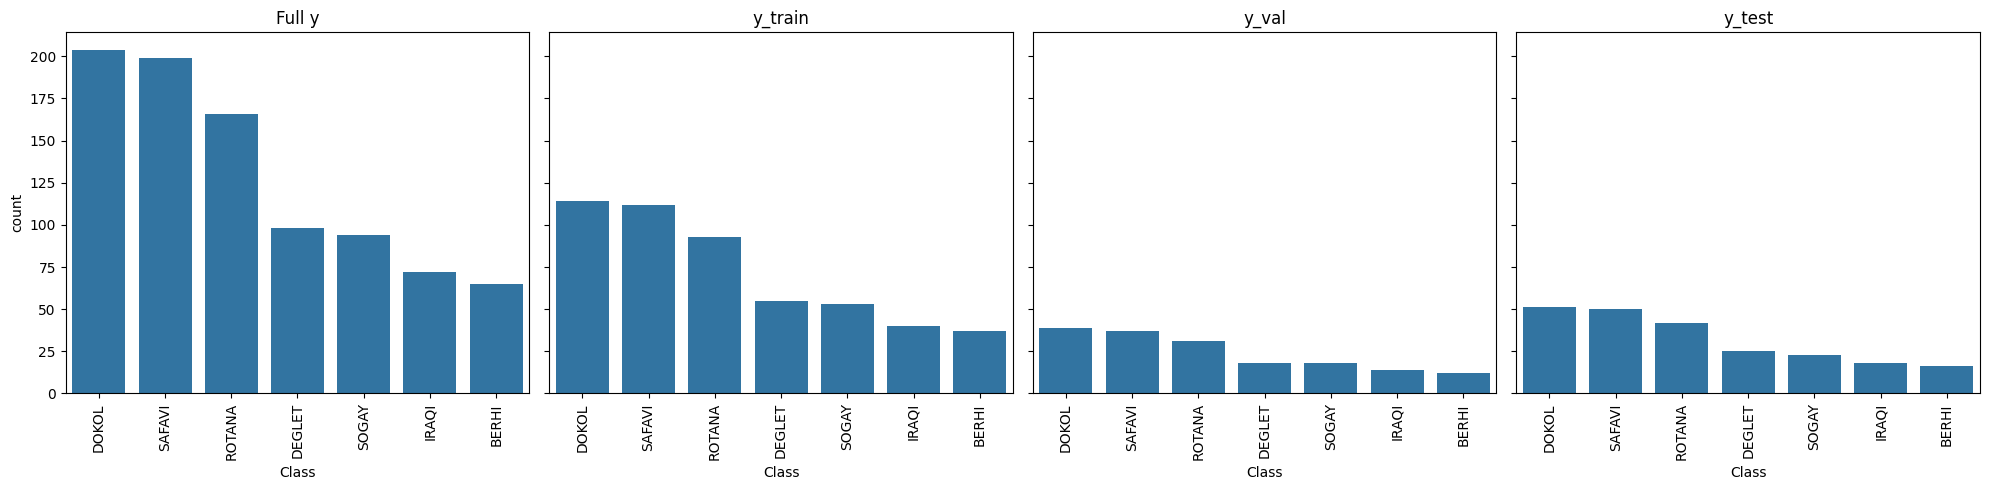

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a figure with 4 subplots side-by-side
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)

# Define the datasets and their titles
datasets = {
    "Full y": y,
    "y_train": y_train,
    "y_val": y_val,
    "y_test": y_test
}

# Loop through and plot each countplot
for i, (title, data) in enumerate(datasets.items()):
    sns.countplot(x=data, ax=axes[i], order=y.value_counts().index)
    axes[i].set_title(title)
    axes[i].tick_params(axis='x', rotation=90) # Rotate class labels if they overlap

plt.tight_layout()
plt.show()

# 7. Feature Scaling Pipeline Definition
We define a Scikit-Learn `Pipeline` with `StandardScaler` to normalize our numerical features, alongside a list containing the names of all 34 predictive features.

In [8]:
preprocess=Pipeline([("scaling",StandardScaler())])
cols=['AREA', 'PERIMETER', 'MAJOR_AXIS', 'MINOR_AXIS', 'ECCENTRICITY',
       'EQDIASQ', 'SOLIDITY', 'CONVEX_AREA', 'EXTENT', 'ASPECT_RATIO',
       'ROUNDNESS', 'COMPACTNESS', 'SHAPEFACTOR_1', 'SHAPEFACTOR_2',
       'SHAPEFACTOR_3', 'SHAPEFACTOR_4', 'MeanRR', 'MeanRG', 'MeanRB',
       'StdDevRR', 'StdDevRG', 'StdDevRB', 'SkewRR', 'SkewRG', 'SkewRB',
       'KurtosisRR', 'KurtosisRG', 'KurtosisRB', 'EntropyRR', 'EntropyRG',
       'EntropyRB', 'ALLdaub4RR', 'ALLdaub4RG', 'ALLdaub4RB']

# 8. Column Transformation & Label Encoding
We apply our scaling pipeline across the training, validation, and test subsets using a `ColumnTransformer`, and encode our categorical date fruit class labels into integer targets.

In [9]:
final_stage=ColumnTransformer(transformers=[("scaling stage",preprocess,cols)])
X_train_scaled=final_stage.fit_transform(X_train)
X_test_scaled=final_stage.transform(X_test)
X_val_scaled=final_stage.transform(X_val)

# for y
encoder = LabelEncoder()
y_train_encoded = encoder.fit_transform(y_train)
y_val_encoded = encoder.transform(y_val)
y_test_encoded = encoder.transform(y_test)

# 9. Deep Neural Network Architecture & Training
We construct a sequential Multi-Layer Perceptron (ANN) with staggered Dropout regularization layers to prevent overfitting, compile it using the Adam optimizer and sparse categorical crossentropy, and train it across 50 epochs.

In [10]:
ANN=Sequential([
    Input(shape=(34,)),
    Dense(256,activation="relu"),
    Dropout(0.3),
    Dense(128,activation="relu"),
    Dropout(0.3),
    Dense(64,activation="relu"),
    Dropout(0.2),
    Dense(32,activation="relu"),
    Dropout(0.1),
    Dense(32,activation="relu"),
    Dropout(0.1),
    Dense(7,activation="softmax")
    ])


# NOW COMPILATION OF ANN

ANN.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

# TRAINING THE MODEL (FIT):-
history=ANN.fit(X_train_scaled,y_train_encoded,
        validation_data=(X_val_scaled,y_val_encoded),
        epochs=50,
        batch_size=16,verbose=1)
ANN.summary()

Epoch 1/50


2026-10-25 09:19:27.557481: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.3889 - loss: 1.6087 - val_accuracy: 0.6982 - val_loss: 1.0995
Epoch 2/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6567 - loss: 1.0000 - val_accuracy: 0.7278 - val_loss: 0.6644
Epoch 3/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6865 - loss: 0.7269 - val_accuracy: 0.7456 - val_loss: 0.5829
Epoch 4/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7341 - loss: 0.6514 - val_accuracy: 0.7574 - val_loss: 0.5172
Epoch 5/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7976 - loss: 0.5637 - val_accuracy: 0.7870 - val_loss: 0.4821
Epoch 6/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8115 - loss: 0.4764 - val_accuracy: 0.8521 - val_loss: 0.4179
Epoch 7/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8313 - loss: 0.4536 - val_accuracy: 0.7988 - val_loss: 0.4270
Epoch 8/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8373 - loss: 0.4218 - val_accuracy: 0.8402 - val_loss: 0.4306
Ep

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         8,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,439 (626.72 KB)

 Trainable params: 53,479 (208.90 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 106,960 (417.82 KB)

# 10. Model Evaluation on Test Data
We evaluate our trained neural network against the unseen test dataset to measure overall loss and generalization accuracy.

In [11]:
test_loss, test_accuracy = ANN.evaluate(X_test_scaled, y_test_encoded)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9467 - loss: 0.2186 
Test Loss: 0.2186
Test Accuracy: 0.9467


# 11. Multi-Class Classification Report
We generate predicted probabilities, convert them to integer class predictions, and output a detailed classification report showcasing precision, recall, and F1-scores for each individual date variety.

In [12]:
y_preds_proba=ANN.predict(X_test_scaled)
y_preds=np.argmax(y_preds_proba,axis=1)
print(classification_report(y_test_encoded,y_preds,target_names=encoder.classes_))

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
              precision    recall  f1-score   support

       BERHI       1.00      1.00      1.00        16
      DEGLET       0.87      0.80      0.83        25
       DOKOL       0.98      0.96      0.97        51
       IRAQI       1.00      1.00      1.00        18
      ROTANA       0.95      1.00      0.98        42
      SAFAVI       0.94      1.00      0.97        50
       SOGAY       0.86      0.78      0.82        23

    accuracy                           0.95       225
   macro avg       0.94      0.93      0.94       225
weighted avg       0.95      0.95      0.95       225



# 12. Test Set Accuracy Score
We compute the final exact accuracy score of our model on the test dataset.

In [13]:
print(accuracy_score(y_test_encoded,y_preds))

0.9466666666666667


# 13. Model Topology Export
We generate and export a visual diagram of our neural network architecture showing layer shapes and parameter counts.

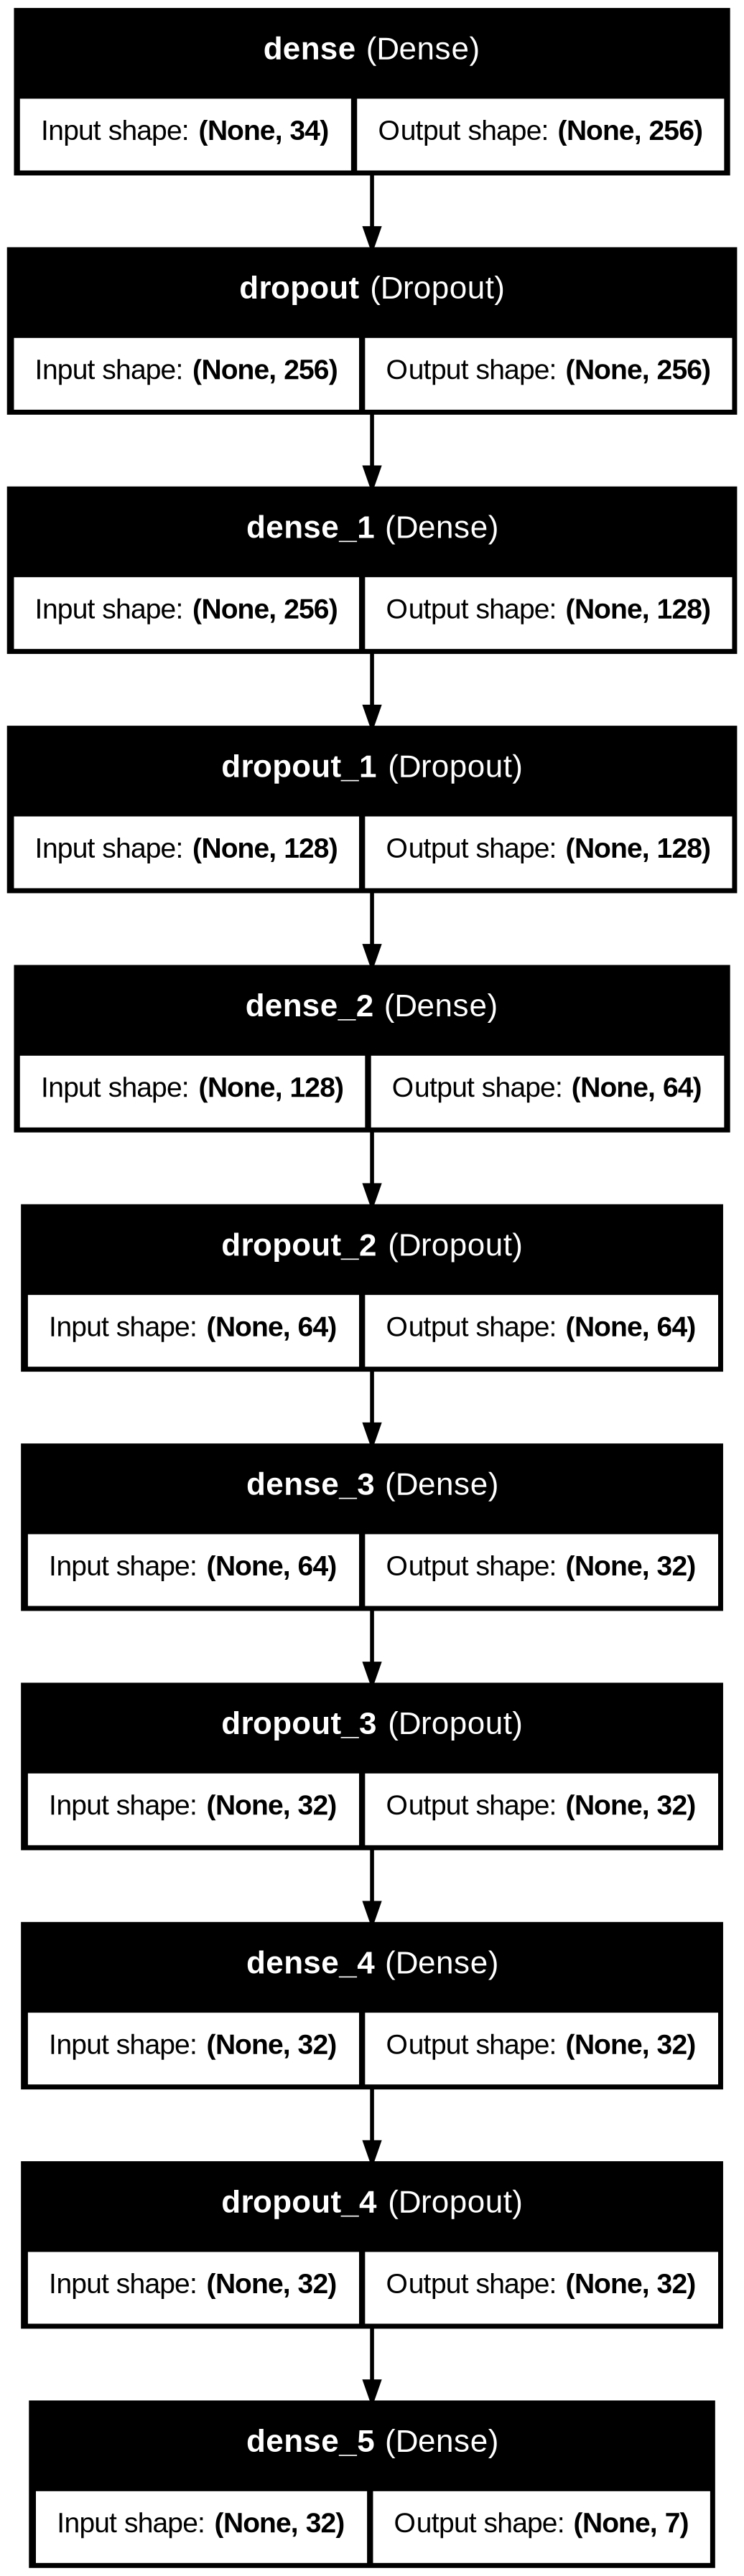

In [14]:
from keras.utils import plot_model
plot_model(ANN , to_file='model.png', show_shapes=True, show_layer_names=True)

# 14. Training & Validation History Plotting
We extract the history object to plot side-by-side curves tracking training vs. validation accuracy and loss across epochs, allowing us to visually inspect learning dynamics and confirm the absence of overfitting.

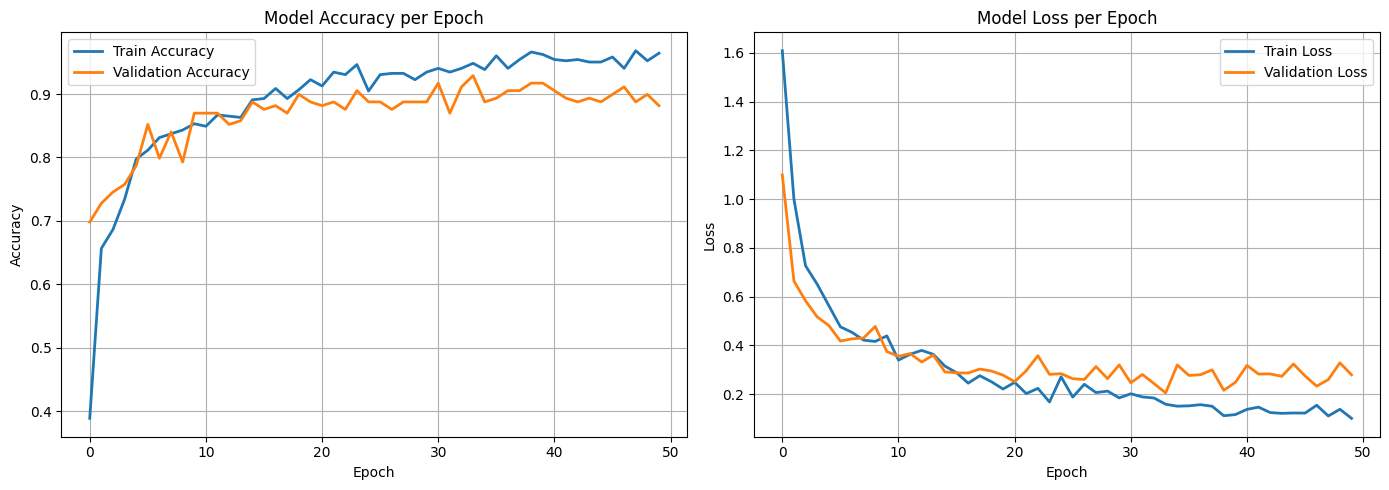

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Training & Validation Accuracy
axes[0].plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
axes[0].set_title('Model Accuracy per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

# Plot Training & Validation Loss
axes[1].plot(history.history['loss'], label='Train Loss', linewidth=2)
axes[1].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
axes[1].set_title('Model Loss per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Key Insights: Training & Validation Dynamics
* **Tight Convergence:** Both training and validation metrics march closely together, with validation accuracy peaking near **91%–92%** without diverging from the training trajectory.
* **Effective Regularization:** The staggered dropout rates successfully prevented the network from memorizing the training set, ensuring robust generalization to unseen data.

# 15. Confusion Matrix Generation
We compute a confusion matrix comparing true labels against predicted labels and visualize it using a Seaborn heatmap to identify specific inter-class misclassifications.

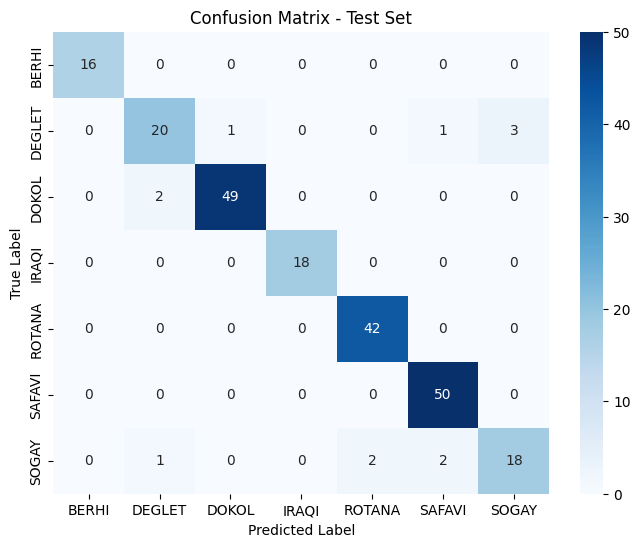

In [16]:
# Generate the confusion matrix
cm = confusion_matrix(y_test_encoded, y_preds)

# Plot using Seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=encoder.classes_, 
            yticklabels=encoder.classes_)
plt.title('Confusion Matrix - Test Set')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### Key Insights: Confusion Matrix Analysis
* **High Diagonal Dominance:** The vast majority of samples fall along the main diagonal, confirming strong correct classifications across categories like `BERHI`, `DOKOL`, and `SAFAVI`.
* **Inter-Class Similarity:** Minor misclassifications occur primarily between visually similar fruit varieties (such as `DEGLET` and `SOGAY`), which reflects subtle morphological overlaps in their feature distributions.

# 16. SHAP Interpretability Analysis
We initialize a SHAP `KernelExplainer` using a background sample of our training data and compute class-specific feature importance bar plots to uncover which geometric and color attributes drive predictions for each date variety.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


  0%|          | 0/20 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1984/1984 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1984/1984 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1984/1984 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1984/1984 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1984/1984 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1984/1984 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1984/1984 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1984/1984 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1984/1984 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1984/1984 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1984/1984 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1984/1984 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 

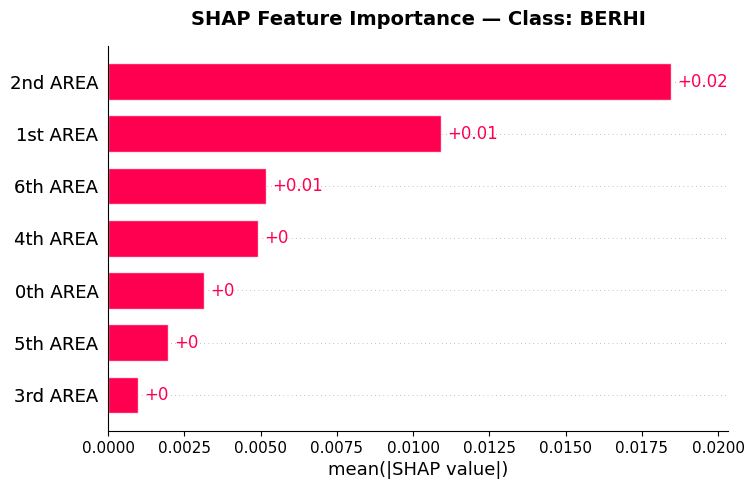


--- SHAP Feature Importance for Class: DEGLET ---


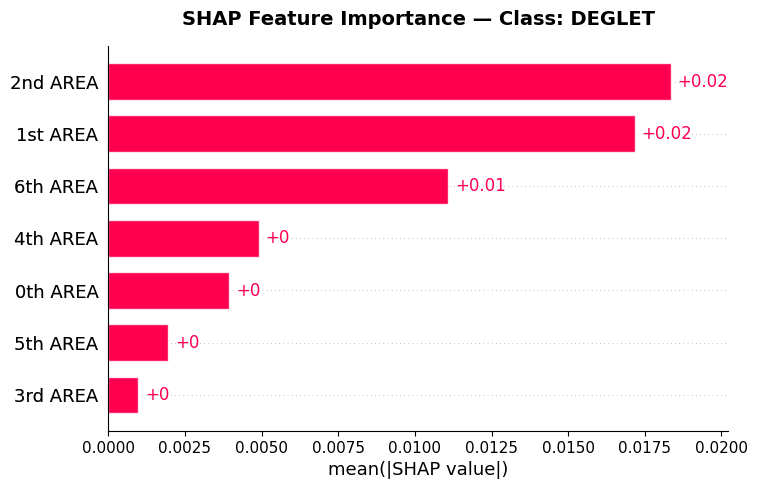


--- SHAP Feature Importance for Class: DOKOL ---


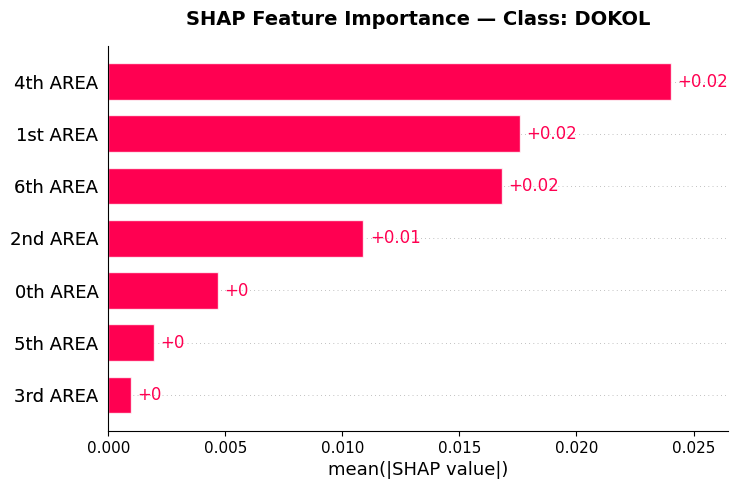


--- SHAP Feature Importance for Class: IRAQI ---


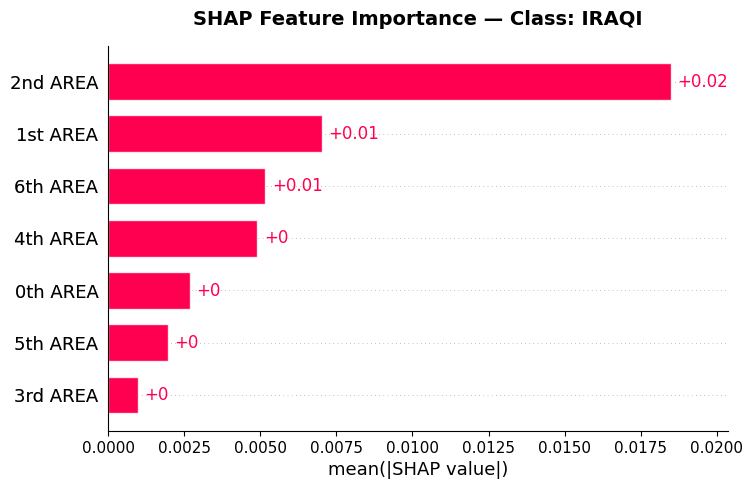


--- SHAP Feature Importance for Class: ROTANA ---


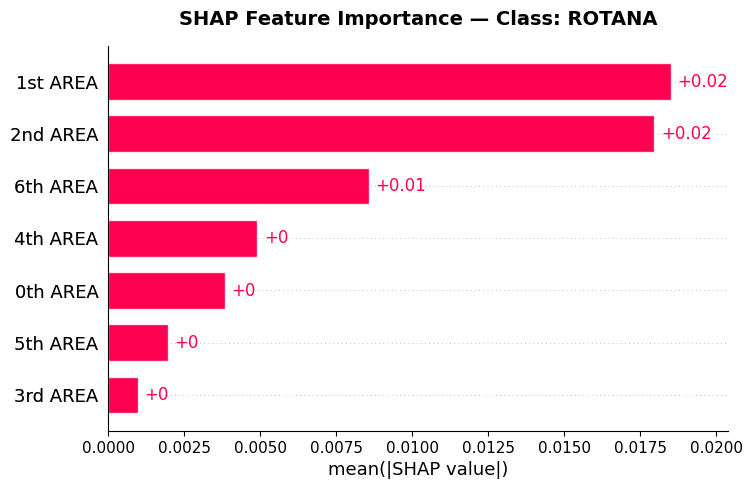


--- SHAP Feature Importance for Class: SAFAVI ---


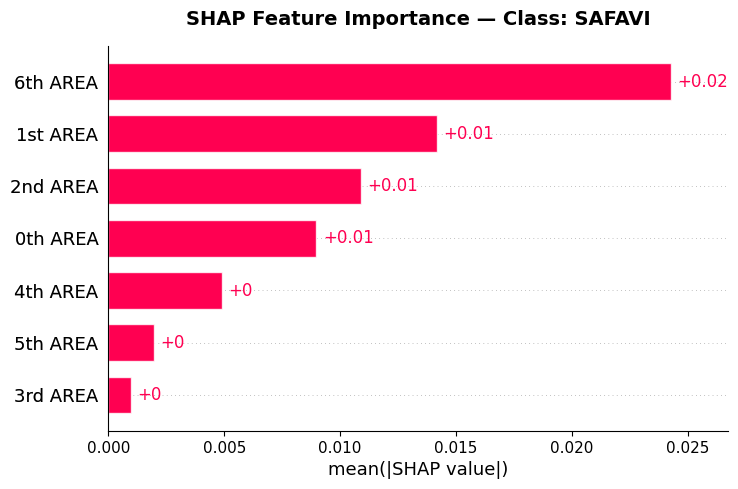


--- SHAP Feature Importance for Class: SOGAY ---


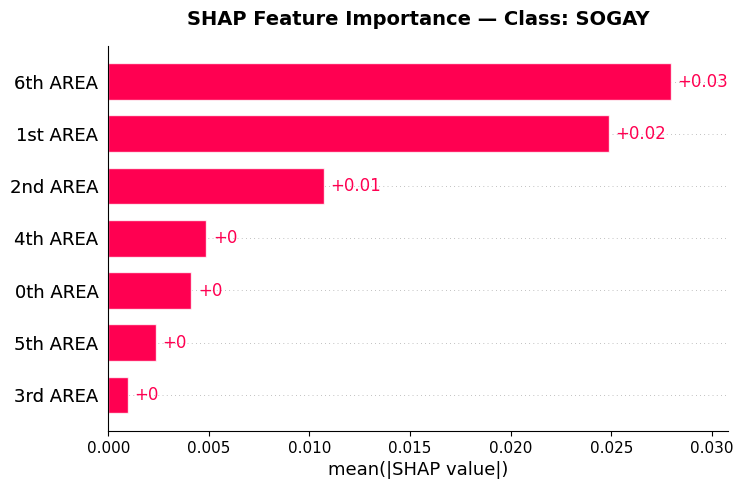

In [17]:
import shap
import numpy as np

# 1. Background sample for KernelExplainer
background = X_train_scaled[:30]

# 2. Prediction wrapper function
def model_predict(x):
    return ANN.predict(x)

# 3. Initialize and compute SHAP values
explainer = shap.KernelExplainer(model_predict, background)
test_subset = X_test_scaled[:20]
shap_values = explainer.shap_values(test_subset)

# 4. Loop through each class and plot using the explicit bar plot function
for class_idx, class_name in enumerate(encoder.classes_):
    print(f"\n--- SHAP Feature Importance for Class: {class_name} ---")
    
    # Create a shap.Explanation object to safely bypass legacy matrix dimension checks
    class_explanation = shap.Explanation(
        values=shap_values[class_idx],
        data=test_subset,
        feature_names=cols
    )
    
    # Plot using modern SHAP bar plot
    shap.plots.bar(class_explanation, max_display=10, show=False)
    
    # Add a bold, large title right onto the plot canvas
    plt.title(f"SHAP Feature Importance — Class: {class_name}", fontsize=14, fontweight='bold', pad=15)
    plt.show()

### Key Insights: SHAP Feature Interpretability
* **Class-Specific Drivers:** The model relies on distinct combinations of physical dimensions (like `AREA`, `PERIMETER`, and `MAJOR_AXIS`) and color metrics (such as `MeanRR` and texture coefficients) to distinguish individual date varieties.
* **Transparent Decisions:** Rather than acting as a total black box, SHAP localizes exactly which physical and color properties push the neural network toward or away from specific class predictions.

# 17. Practical Business & Agricultural Analysis
To translate our machine learning model into actionable insights, let's explore three critical business questions regarding date fruit grading, morphological separation, and color clustering.

# Q1: How effectively do Area and Perimeter separate different date fruit varieties?

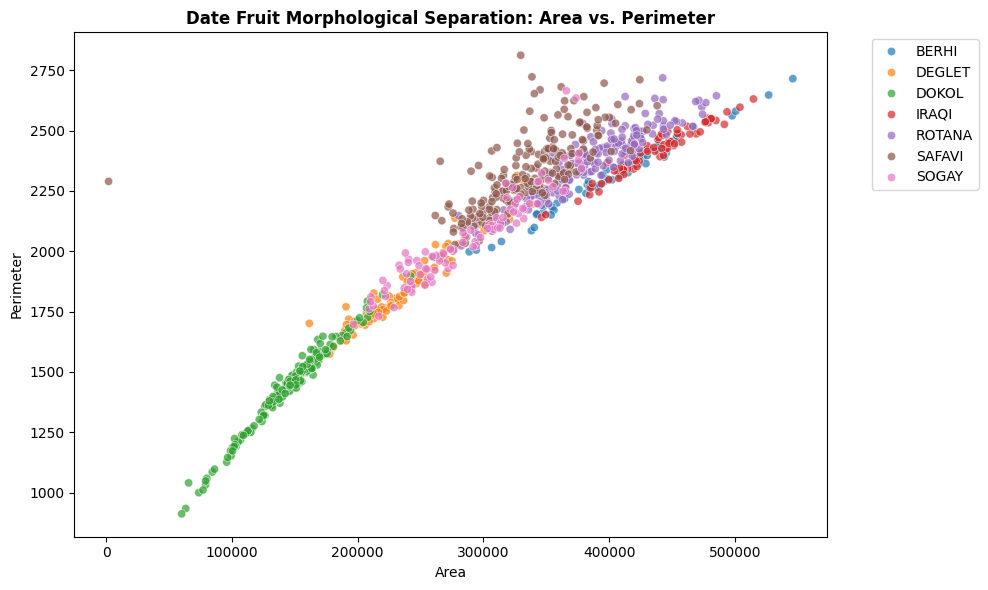

In [18]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='AREA', y='PERIMETER', hue='Class', palette='tab10', alpha=0.7)
plt.title('Date Fruit Morphological Separation: Area vs. Perimeter', fontsize=12, fontweight='bold')
plt.xlabel('Area')
plt.ylabel('Perimeter')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Business Insight: Morphological Grading
* **Linear Scale Correlation:** Scatter plotting `AREA` against `PERIMETER` confirms a strong direct proportionality across varieties, verifying that physical dimensions provide a robust primary sorting axis for automated agricultural grading machinery.
* **Boundary Overlaps:** Medium-to-large classes exhibit intersecting density regions, highlighting why simple linear thresholding fails and validating the necessity of multi-layered neural networks.

# Q2: How do color profiles (Mean Red vs Mean Green) distribute across date categories?

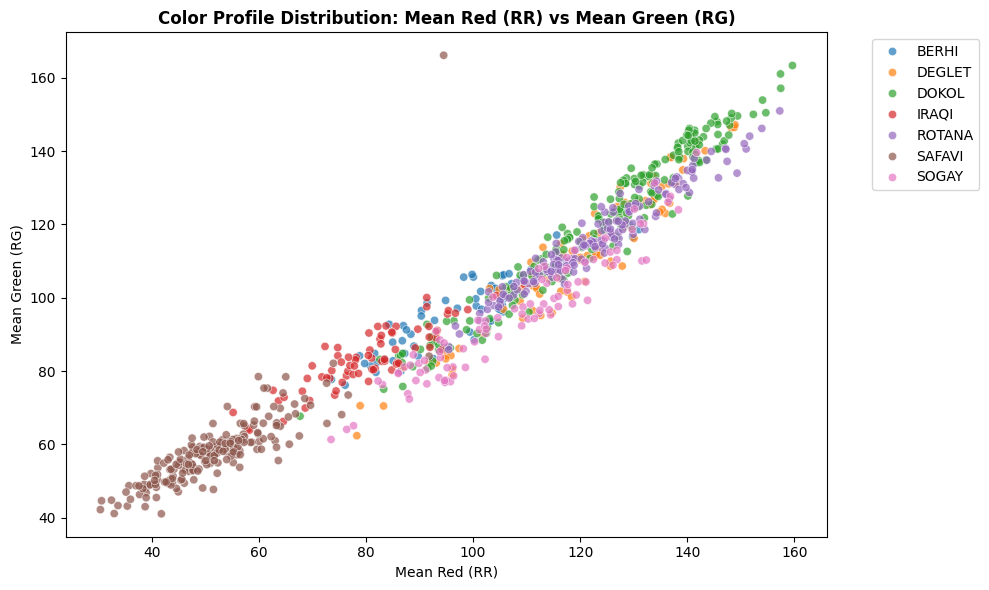

In [19]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='MeanRR', y='MeanRG', hue='Class', palette='tab10', alpha=0.7)
plt.title('Color Profile Distribution: Mean Red (RR) vs Mean Green (RG)', fontsize=12, fontweight='bold')
plt.xlabel('Mean Red (RR)')
plt.ylabel('Mean Green (RG)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Business Insight: Color Clustering & Ripeness
* **Spectral Separability:** The `MeanRR` vs. `MeanRG` distribution demonstrates that optical skin pigmentation sensors can successfully isolate specific date categories prior to physical sizing.
* **Intra-Class Variance:** Dispersion within individual clusters reflects natural variations in surface tones, indicating that color metrics can double as secondary indicators for automated ripeness and defect detection.

# Q3: How does SHAPEFACTOR_1 vary across the different date fruit classes?

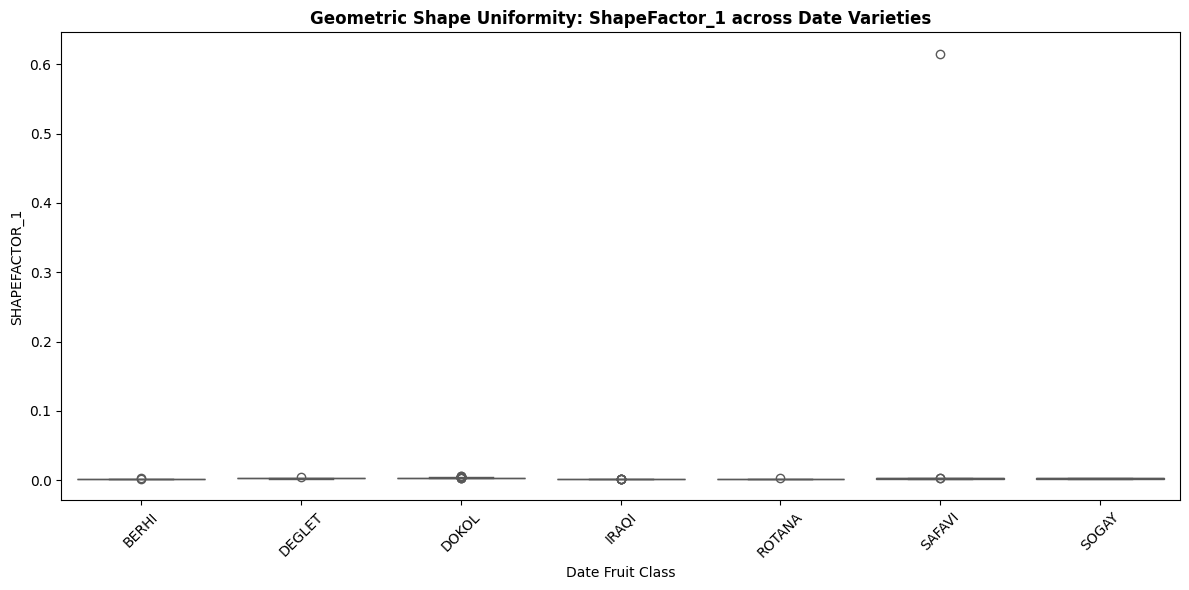

In [20]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='Class', y='SHAPEFACTOR_1', hue='Class', palette='Set2', legend=False)
plt.title('Geometric Shape Uniformity: ShapeFactor_1 across Date Varieties', fontsize=12, fontweight='bold')
plt.xlabel('Date Fruit Class')
plt.ylabel('SHAPEFACTOR_1')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Business Insight: Shape Factor Uniformity
* **Geometric Consistency:** Boxplots of `SHAPEFACTOR_1` indicate that select varieties maintain rigid, uniform structural proportions, offering a highly reliable feature for class identification.
* **Morphological Skewness:** Minor variations across classes highlight natural biological irregularities, explaining why your ANN model leverages multi-feature fusion rather than relying on a single geometric shape factor.